# 04 : Evaluate on the test set (once)

Purpose: the one and only place `test.csv` is opened. Evaluates M0 and
M1 on test, reports the four required figures, the M0 vs M1 comparison
at both the untuned threshold and each model's validation-selected
threshold, the per-corpus breakdown for M1, and the false-positive
review. Author: Colile Sibanda.

**Test-set invariant:** no threshold is chosen here : `select_threshold`
runs on `validation.csv` only, then is applied unchanged to test.

In [1]:
import subprocess
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import torch

# Notebooks run with the kernel's cwd set to notebooks/; load_config() reads
# a path relative to the repo root, so move up to it first.
import os

_repo_root = Path.cwd()
while not (_repo_root / "pyproject.toml").exists():
    _repo_root = _repo_root.parent
os.chdir(_repo_root)

from phishlens.config.loader import load_config
from phishlens.config.seeding import set_global_seed
from phishlens.data.splitter import config_hash
from phishlens.evaluation.metrics import compute_metrics, select_threshold
from phishlens.evaluation.persistence import save_metrics
from phishlens.evaluation.plots import (
    plot_confusion_matrix,
    plot_loss_curve,
    plot_precision_recall,
    plot_roc,
)
from phishlens.evaluation.reporting import metrics_table, per_corpus_table
from phishlens.features.encoder import encode
from phishlens.features.vocabulary import Vocabulary
from phishlens.models.baseline import build_baseline
from phishlens.models.text_cnn import build_text_cnn
from phishlens.training.checkpoint import restore_best
from phishlens.training.loop import CHECKPOINT_FILE, METRIC_FILE

config = load_config()
set_global_seed(config.seed)
commit_hash = subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip()

print(f"Config seed: {config.seed}")
print(f"Commit hash: {commit_hash}")
print(f"Run date: {datetime.now().isoformat(timespec='seconds')}")

Config seed: 42
Commit hash: 3b9f8b19fd8d966b153bb25a543109396572f47f
Run date: 2026-10-18T10:04:21


## Load all three splits

`test.csv` is opened here, once, per the invariant above.

In [2]:
processed_dir = Path(config.paths.processed)
train_df = pd.read_csv(processed_dir / "train.csv")
validation_df = pd.read_csv(processed_dir / "validation.csv")
test_df = pd.read_csv(processed_dir / "test.csv")

label_column = config.data.label_column

print(f"Train rows: {len(train_df)}")
print(f"Validation rows: {len(validation_df)}")
print(f"Test rows: {len(test_df)}")
print(f"Test positive rate: {test_df[label_column].mean():.4f}")

Train rows: 57736
Validation rows: 12372
Test rows: 12373
Test positive rate: 0.5199


## Rebuild M1 and restore the best checkpoint

The vocabulary and weights come from `03_train_cnn.ipynb` : this notebook
does not retrain.

In [3]:
vocabulary = Vocabulary.load(Path(config.paths.models) / "vocabulary.json")
model = build_text_cnn(vocab_size=vocabulary.size(), config=config)

checkpoint_path = Path(config.paths.models) / CHECKPOINT_FILE
restore_best(model, checkpoint_path)
model.eval()

print(f"Restored checkpoint: {checkpoint_path}")


# Scoring a whole split in one forward pass needs a multi-gigabyte activation
# tensor; fixed-size batches cap peak memory at one batch. The model is in
# eval mode with no batch-dependent layers, so batching changes probabilities
# only by float32 rounding (about 1e-7): no prediction or reported metric moves.
INFERENCE_BATCH_SIZE = 512


def predict_m1(texts: list[str]) -> np.ndarray:
    """Encode texts and return M1 probabilities from the restored model.

    Inputs: texts : cleaned text strings from any split.
    Output: 1-D numpy array of sigmoid probabilities for the positive class.
    """
    sequences = encode(texts, vocabulary, config)
    chunks = []
    with torch.no_grad():
        for start in range(0, len(sequences), INFERENCE_BATCH_SIZE):
            batch = torch.from_numpy(sequences[start:start + INFERENCE_BATCH_SIZE])
            chunks.append(torch.sigmoid(model(batch)).numpy())
    return np.concatenate(chunks)

Restored checkpoint: artifacts\models\text_cnn_best.pt


## Refit M0 on train, per `02_baseline.ipynb`

M0 has no persisted artefact from `02_baseline.ipynb`, so it is refit here on the same
training split for a fair test-set comparison.

In [4]:
m0_pipeline = build_baseline(config)
m0_pipeline.fit(train_df["text"].tolist(), train_df[label_column].to_numpy())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",False
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",<function bui...0020E2137A160>
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",<function tok...0020E21179620>
,"token_pattern token_pattern: str, default=r""(?u)\\b\\w\\w+\\b""Regular expression denoting what constitutes a ""token"", only usedif ``analyzer == 'word'``. The default regexp selects tokens of 2or more alphanumeric characters (punctuation is completely ignoredand always treated as a token separator).If there is a capturing group in token_pattern then thecaptured group content, not the entire match, becomes the token.At most one capturing group is permitted.",None
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"


## Score both models on validation and test

In [5]:
m0_val_probabilities = m0_pipeline.predict_proba(validation_df["text"].tolist())[:, 1]
m0_test_probabilities = m0_pipeline.predict_proba(test_df["text"].tolist())[:, 1]

m1_val_probabilities = predict_m1(validation_df["text"].tolist())
m1_test_probabilities = predict_m1(test_df["text"].tolist())

val_labels = validation_df[label_column].to_numpy()
test_labels = test_df[label_column].to_numpy()

## Select thresholds on validation only

`select_threshold` never sees test. The untuned 0.5 and the selected
threshold are both reported below.

In [6]:
default_threshold = config.evaluation.decision_threshold
m0_selected_threshold = select_threshold(val_labels, m0_val_probabilities, objective="macro_f1")
m1_selected_threshold = select_threshold(val_labels, m1_val_probabilities, objective="macro_f1")

print(f"Untuned threshold: {default_threshold}")
print(f"M0 selected threshold (validation): {m0_selected_threshold:.4f}")
print(f"M1 selected threshold (validation): {m1_selected_threshold:.4f}")

Untuned threshold: 0.5
M0 selected threshold (validation): 0.5055
M1 selected threshold (validation): 0.5698


## Test-set metrics at both thresholds

In [7]:
m0_metrics_default = compute_metrics(test_labels, m0_test_probabilities, default_threshold)
m1_metrics_default = compute_metrics(test_labels, m1_test_probabilities, default_threshold)

m0_metrics_selected = compute_metrics(test_labels, m0_test_probabilities, m0_selected_threshold)
m1_metrics_selected = compute_metrics(test_labels, m1_test_probabilities, m1_selected_threshold)

## M0 vs M1 comparison : untuned threshold (0.5)

In [8]:
metrics_table(
    {
        "M0 TF-IDF + LogReg": m0_metrics_default,
        "M1 Text-CNN": m1_metrics_default,
    }
)

,accuracy,precision,recall,f1,macro_f1,auc_roc,average_precision
model,,,,,,,
M0 TF-IDF + LogReg,0.9857,0.9853,0.9873,0.9863,0.9857,0.9988,0.9989
M1 Text-CNN,0.9862,0.9802,0.9935,0.9868,0.9861,0.9991,0.9992


## M0 vs M1 comparison : validation-selected threshold

In [9]:
metrics_table(
    {
        "M0 TF-IDF + LogReg": m0_metrics_selected,
        "M1 Text-CNN": m1_metrics_selected,
    }
)

,accuracy,precision,recall,f1,macro_f1,auc_roc,average_precision
model,,,,,,,
M0 TF-IDF + LogReg,0.9856,0.9857,0.9866,0.9862,0.9856,0.9988,0.9989
M1 Text-CNN,0.9871,0.9829,0.9925,0.9877,0.9871,0.9991,0.9992


## The four required figures (M1, test split, selected threshold)

C:\Users\sikhu\AppData\Local\Temp\ipykernel_28276\2616511997.py:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plot_roc(test_labels, m1_test_probabilities, "M1 Text-CNN", "test").show()


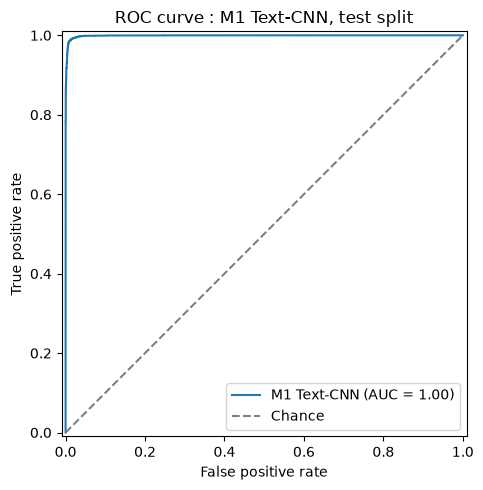

In [10]:
plot_roc(test_labels, m1_test_probabilities, "M1 Text-CNN", "test").show()

C:\Users\sikhu\AppData\Local\Temp\ipykernel_28276\2833842229.py:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plot_precision_recall(test_labels, m1_test_probabilities, "M1 Text-CNN", "test").show()


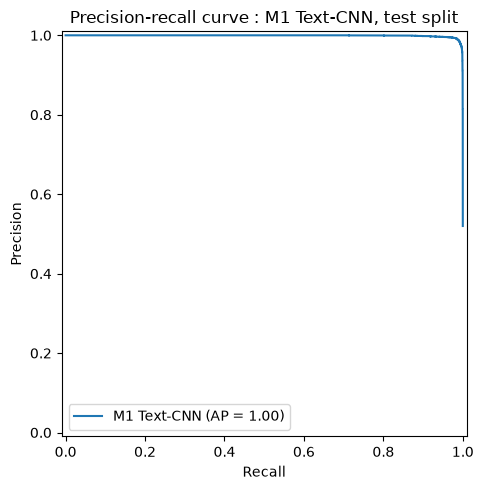

In [11]:
plot_precision_recall(test_labels, m1_test_probabilities, "M1 Text-CNN", "test").show()

C:\Users\sikhu\AppData\Local\Temp\ipykernel_28276\1300930192.py:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plot_confusion_matrix(m1_metrics_selected, "M1 Text-CNN", "test").show()


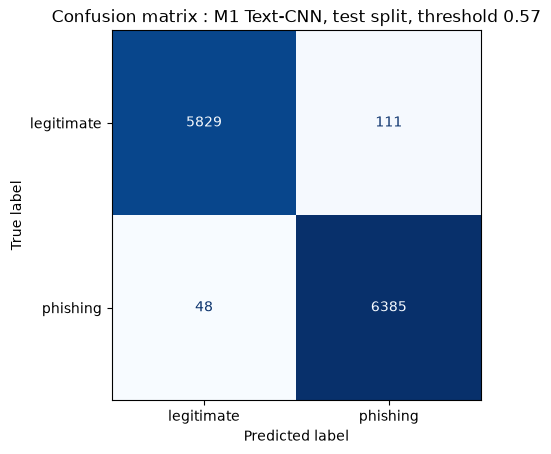

In [12]:
plot_confusion_matrix(m1_metrics_selected, "M1 Text-CNN", "test").show()

C:\Users\sikhu\AppData\Local\Temp\ipykernel_28276\4186511394.py:3: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plot_loss_curve(training_history, "M1 Text-CNN").show()


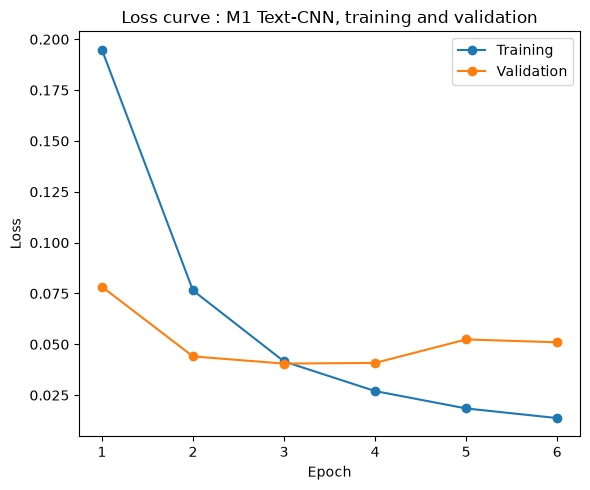

In [13]:
training_log_path = Path(config.paths.metrics) / METRIC_FILE
training_history = pd.read_csv(training_log_path).to_dict("records")
plot_loss_curve(training_history, "M1 Text-CNN").show()

## Per-corpus breakdown for M1 (test split, selected threshold)

In [14]:
per_corpus_metrics = {}
for corpus, group in test_df.groupby("corpus"):
    group_probabilities = predict_m1(group["text"].tolist())
    per_corpus_metrics[corpus] = compute_metrics(
        group[label_column].to_numpy(), group_probabilities, m1_selected_threshold
    )

per_corpus_table(per_corpus_metrics)

,accuracy,precision,recall,f1,macro_f1,auc_roc,average_precision
corpus,,,,,,,
CEAS_08,0.9934,0.9911,0.9973,0.9942,0.9933,0.9997,0.9998
Enron,0.9826,0.9763,0.9866,0.9814,0.9825,0.9984,0.9981
Ling,0.9614,0.8077,0.9844,0.8873,0.9320,0.9967,0.9834
Nazario,0.9805,1.0000,0.9805,0.9901,0.4951,NaN,NaN
Nigerian_Fraud,0.9979,1.0000,0.9979,0.9989,0.4995,NaN,NaN
SpamAssasin,0.9758,0.9396,0.9803,0.9595,0.9711,0.9949,0.9888


**Reading Nazario and Nigerian_Fraud:** both corpora are 100% phishing in
every split (see `docs/dataset-card.md`) : there are no legitimate rows to score. `auc_roc` and
`average_precision` are correctly NaN (undefined with a single class
present, per `compute_metrics`'s documented behaviour) and `macro_f1`
collapses to roughly half of the true positive-class F1, because macro
averaging still divides by two classes even though the legitimate class
has zero support here. Precision, recall and accuracy on the phishing
class itself are the numbers that mean something for these two rows; they
are near-perfect. This is a property of the corpus, not a model failure.

## False-positive review (M1, test split, selected threshold)

Legitimate emails (label 0) the model scored above the operating
threshold : the qualitative evidence for the report's error analysis.

In [15]:
predictions = (m1_test_probabilities >= m1_selected_threshold).astype(int)
false_positive_mask = (test_labels == 0) & (predictions == 1)

false_positives = test_df.loc[false_positive_mask].copy()
false_positives["probability"] = m1_test_probabilities[false_positive_mask]
false_positives = false_positives.sort_values("probability", ascending=False)

print(f"False positives: {int(false_positive_mask.sum())} of {len(test_df)} test rows")
false_positives[["corpus", "probability", "text"]].head(10)

False positives: 111 of 12373 test rows


,corpus,probability,text
10792,SpamAssasin,0.999651,"Adam dont job for no one, see. A groys gesheft..."
10395,Enron,0.999032,yvan chaxel your name was listed by yvan as a ...
8179,Enron,0.998761,digitize your memories with compaq scanners ti...
10509,CEAS_08,0.996503,Italian Garden Treasures The New York Botanica...
4677,Enron,0.995973,re : grading graders usually follow the follow...
6946,Enron,0.995947,quack ( see attached file : duck hunting . mpe...
4901,Ling,0.994951,"autoantonyms a book that is "" in print "" when ..."
3994,CEAS_08,0.994706,unsubscribe Unsubscribe
5662,Enron,0.994229,"your valpak . com "" print later "" link below i..."
4474,CEAS_08,0.993268,"Toolbar Dear Support, your product looks amazi..."


## Save test-set metrics

M0's test-set numbers are new : `m0_baseline.json` from `02_baseline.ipynb` is
validation-only and must not be overwritten with test numbers.

In [16]:
run_context = {
    "seed": config.seed,
    "commit_hash": commit_hash,
    "config_hash": config_hash(config),
    "split_evaluated": "test",
    "train_rows": len(train_df),
    "validation_rows": len(validation_df),
    "test_rows": len(test_df),
}

save_metrics(
    m1_metrics_selected,
    Path(config.paths.metrics) / "m1_text_cnn.json",
    {**run_context, "model": "m1_text_cnn", "threshold_policy": "validation_selected_macro_f1"},
)
save_metrics(
    m0_metrics_selected,
    Path(config.paths.metrics) / "m0_test.json",
    {**run_context, "model": "m0_tfidf_logreg", "threshold_policy": "validation_selected_macro_f1"},
)

print("Metrics written to artifacts/metrics/m1_text_cnn.json and m0_test.json")

Metrics written to artifacts/metrics/m1_text_cnn.json and m0_test.json
